# Karta zaliczeniowa: nieparametryczne odpowiedniki ANOVA jedno- i wieloczynnikowej

**Przedmiot:** Statystyka  
**Kierunek:** Informatyka, studia magisterskie  
**Forma:** praca zaliczeniowa w Jupyter Notebook  


**Numer Indeksu Studenta**: 142706

## Cel
Dla przygotowanych zbiorów danych:
1. rozpoznaj plan badania,
2. uzasadnij wybór testu nieparametrycznego,
3. wykonaj test globalny,
4. wykonaj analizę post hoc,
5. podaj wielkość efektu tam, gdzie ma to sens,
6. napisz krótką interpretację wyniku.

## Zasady
- Pracujesz **na danych z pliku Excel**.
- Analizy wykonujesz **bez własnych funkcji pomocniczych** — bezpośrednio w kolejnych komórkach.
- Używaj tylko podstawowych bibliotek i funkcji pokazanych na zajęciach.
- Nie używaj `itertools`.
- W interpretacji odwołuj się zarówno do **wyniku statystycznego**, jak i do **kontekstu problemu**.
- Tam, gdzie to możliwe, wykonaj również **wizualizację** oraz sprawdź **skośność**.

## Kryteria oceny
- poprawny dobór testu: $20\%$,
- poprawność kodu i wyników: $35\%$,
- post hoc i wielkość efektu: $20\%$,
- interpretacja i opis statystyczny: $25\%$.


## Plik z danymi

Wraz z notebookiem otrzymujesz plik:

`dane_zaliczenie_nieparametryczne_anova.xlsx`

Arkusze:
- `kruskal`
- `friedman`
- `scheirer_ray_hare`
- `cochran_q`


## Import bibliotek

Użyj tylko bibliotek potrzebnych do:
- odczytu danych,
- obliczeń statystycznych,
- korekty wielokrotnych porównań,
- wykonania wykresów.


In [19]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")


## Odczyt danych z pliku Excel

Wczytaj wszystkie potrzebne arkusze do osobnych obiektów:
- `kw_df`
- `friedman_wide`
- `srh_df`
- `cochran_df`


In [20]:
plik_excel = "dane_zaliczenie_nieparametryczne_anova_746378.xlsx"

kw_df = pd.read_excel(plik_excel, sheet_name="kruskal")
friedman_wide = pd.read_excel(plik_excel, sheet_name="friedman")
srh_df = pd.read_excel(plik_excel, sheet_name="scheirer_ray_hare")
cochran_df = pd.read_excel(plik_excel, sheet_name="cochran_q")


In [21]:
kw_df.head(), friedman_wide.head(), srh_df.head(), cochran_df.head()


(  metoda  czas_s
 0      A 76.0300
 1      A 58.8100
 2      A 68.8000
 3      A 73.6000
 4      A 64.9300,
    student_id   IDE_A   IDE_B   IDE_C
 0           1 64.9900 65.1300 69.8900
 1           2 81.0900 70.2100 66.0500
 2           3 80.0000 73.8900 66.4100
 3           4 75.2200 69.1300 64.9400
 4           5 74.2200 72.8700 65.0600,
   storage    load  latency_ms
 0     HDD  Niskie    100.5100
 1     HDD  Niskie     99.0100
 2     HDD  Niskie     81.4000
 3     HDD  Niskie     69.8200
 4     HDD  Niskie     79.5100,
    alg_A  alg_B  alg_C
 0      0      1      1
 1      1      1      1
 2      1      0      1
 3      0      1      0
 4      1      1      1)

# Część A. Jednoczynnikowa ANOVA dla grup niezależnych → Kruskal–Wallis

## Kontekst
Badamy **czas wykonania zadania programistycznego** w trzech grupach:
- `A`,
- `B`,
- `C`.

## Twoje zadania
1. Opisz, dlaczego nie stosujemy klasycznej jednoczynnikowej ANOVA.
2. Zbadaj skośność w grupach.
3. Wykonaj wykres(y) porównujące grupy.
4. Wykonaj test Kruskala–Wallisa.
5. Oblicz wielkość efektu:
   $$
   \varepsilon^2 = \frac{H-k+1}{n-k}
   $$
6. Wykonaj post hoc metodą Dunna z korektą Holma.
7. Napisz krótki wniosek.


### A1. Uzasadnienie wyboru testu
W tej komórce tekstowej zapisz:
- jaki to jest plan badania,
- jaka jest skala zmiennej zależnej,
- czy grupy są zależne czy niezależne,
- dlaczego test rangowy jest uzasadniony.


To jest plan jednoczynnikowy dla grup niezależnych. Zmienna zależna ma skalę ilorazową i opisuje czas wykonania zadania w sekundach. Grupy A, B i C są niezależne. Test Kruskala-Wallisa jest tu uzasadniony, bo rozkłady są asymetryczne, a analiza nie wymaga założenia normalności.

### A2. Statystyki opisowe i skośność
Policz co najmniej:
- liczebność,
- średnią,
- medianę,
- odchylenie standardowe,
- skośność.


In [22]:
kw_skew = (
    kw_df.groupby("metoda")["czas_s"]
    .agg(
        liczebność="count",
        średnia="mean",
        mediana="median",
        odchylenie_std="std",
        skośność=lambda x: stats.skew(x, bias=False)
    )
)

kw_skew


,liczebność,średnia,mediana,odchylenie_std,skośność
metoda,,,,,
A,18,64.8611,64.6050,11.2061,0.3582
B,18,90.2067,86.8150,16.9762,0.8216
C,18,103.4356,106.4050,20.4942,0.6302


### A3. Wizualizacja
Wykonaj co najmniej dwa wykresy, np.:
- boxplot,
- violinplot.


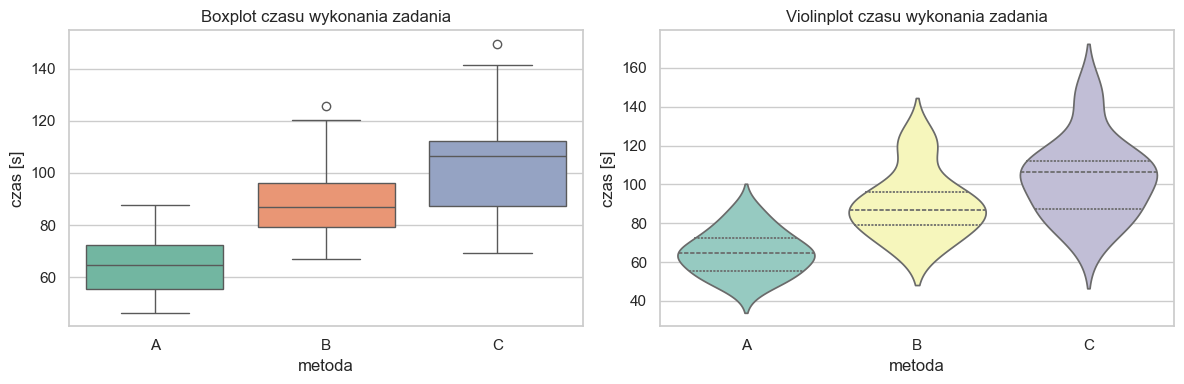

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=kw_df, x="metoda", y="czas_s", ax=axes[0], palette="Set2")
axes[0].set_title("Boxplot czasu wykonania zadania")
axes[0].set_xlabel("metoda")
axes[0].set_ylabel("czas [s]")

sns.violinplot(data=kw_df, x="metoda", y="czas_s", ax=axes[1], palette="Set3", inner="quartile")
axes[1].set_title("Violinplot czasu wykonania zadania")
axes[1].set_xlabel("metoda")
axes[1].set_ylabel("czas [s]")

plt.tight_layout()
plt.show()


### A4. Hipotezy
Zapisz $H_0$ i $H_1$ dla testu Kruskala–Wallisa.


- $H_0$: rozkłady czasu wykonania są takie same we wszystkich trzech grupach A, B i C.
- $H_1$: co najmniej jedna grupa różni się rozkładem czasu wykonania.

### A5. Test globalny i wielkość efektu


In [5]:

H_stat, p_value = stats.kruskal(
    kw_df.loc[kw_df["metoda"] == "A", "czas_s"],
    kw_df.loc[kw_df["metoda"] == "B", "czas_s"],
    kw_df.loc[kw_df["metoda"] == "C", "czas_s"]
)

n = len(kw_df)
k = kw_df["metoda"].nunique()
epsilon_sq = (H_stat - k + 1) / (n - k)

print(f"Statystyka H = {H_stat:.4f}")
print(f"p-value = {p_value:.4f}")
print(f"epsilon^2 = {epsilon_sq:.4f}")


Statystyka H = 29.9021
p-value = 0.0000
epsilon^2 = 0.5471


### A6. Post hoc: Dunn + Holm

Wykonaj porównania par:
- `A` vs `B`,
- `A` vs `C`,
- `B` vs `C`.

Wskazówka: użyj rang, średnich rang, korekty na remisy i rozkładu normalnego.


In [23]:
dunn_data = kw_df[["czas_s", "metoda"]].dropna().copy()
dunn_data["ranga"] = stats.rankdata(dunn_data["czas_s"], method="average")

N = len(dunn_data)
tie_counts = dunn_data["czas_s"].value_counts()
tie_correction = 1 - ((tie_counts**3 - tie_counts).sum() / (N**3 - N))

mean_ranks = dunn_data.groupby("metoda")["ranga"].mean()
group_sizes = dunn_data.groupby("metoda")["ranga"].size()
base_var = N * (N + 1) / 12

rows = []
poziomy = ["A", "B", "C"]

for i in range(len(poziomy) - 1):
    for j in range(i + 1, len(poziomy)):
        g1 = poziomy[i]
        g2 = poziomy[j]

        diff = mean_ranks[g1] - mean_ranks[g2]
        se = np.sqrt(base_var * tie_correction * (1 / group_sizes[g1] + 1 / group_sizes[g2]))
        z_stat = diff / se
        p_uncorrected = 2 * stats.norm.sf(abs(z_stat))

        rows.append((g1, g2, z_stat, p_uncorrected))

kw_posthoc = pd.DataFrame(rows, columns=["grupa_1", "grupa_2", "z", "p_uncorrected"])
kw_posthoc["p_corrected"] = multipletests(kw_posthoc["p_uncorrected"], method="holm")[1]
kw_posthoc.sort_values("p_corrected").reset_index(drop=True)


,grupa_1,grupa_2,z,p_uncorrected,p_corrected
0,A,C,-5.2970,0.0000,0.0000
1,A,B,-3.8244,0.0001,0.0003
2,B,C,-1.4726,0.1409,0.1409


### A7. Wniosek
Napisz w $4$–$6$ zdaniach:
- czy wynik globalny jest istotny,
- jaka jest siła efektu,
- które grupy różnią się między sobą,
- co to oznacza w kontekście problemu.


Test Kruskala-Wallisa był istotny statystycznie: $H = 29.9021$, $p < 0.001$. Wielkość efektu wyniosła $\varepsilon^2 = 0.5471$, co wskazuje na duży efekt. Post hoc Dunna z korektą Holma pokazał istotne różnice między A i B oraz A i C, natomiast para B i C nie różniła się istotnie. W praktyce metoda A była najszybsza, a metoda C najwolniejsza.

# Część B. Jednoczynnikowa ANOVA z powtarzanym pomiarem → Friedman

## Kontekst
Ci sami studenci rozwiązują podobne zadanie w trzech środowiskach:
- `IDE_A`,
- `IDE_B`,
- `IDE_C`.

## Twoje zadania
1. Uzasadnij wybór testu Friedmana.
2. Zbadaj skośność wyników w warunkach.
3. Wykonaj wykres pudełkowy oraz wykres profili.
4. Wykonaj test Friedmana.
5. Oblicz współczynnik zgodności Kendalla:
   $$
   W = \frac{\chi^2_F}{n(k-1)}
   $$
6. Wykonaj post hoc testami Wilcoxona dla prób zależnych z korektą Holma.
7. Napisz wniosek.


In [24]:
friedman_long = friedman_wide.melt(
    id_vars="student_id",
    var_name="środowisko",
    value_name="czas_s"
)

friedman_long.head()


,student_id,środowisko,czas_s
0,1,IDE_A,64.9900
1,2,IDE_A,81.0900
2,3,IDE_A,80.0000
3,4,IDE_A,75.2200
4,5,IDE_A,74.2200


### B1. Uzasadnienie wyboru testu


To jest plan z powtarzanym pomiarem to znaczy, że ci sami studenci wykonują zadanie w trzech środowiskach, więc obserwacje są zależne. Zmienna zależna jest ciągła, a test Friedmana jest właściwy, gdy nie chcemy zakładać normalności i analizujemy kilka pomiarów zależnych.

### B2. Statystyki opisowe i skośność


In [25]:

friedman_skew = (
    friedman_long.groupby("środowisko")["czas_s"]
    .agg(
        liczebność="count",
        średnia="mean",
        mediana="median",
        odchylenie_std="std",
        skośność=lambda x: stats.skew(x, bias=False)
    )
)

friedman_skew


,liczebność,średnia,mediana,odchylenie_std,skośność
środowisko,,,,,
IDE_A,18,78.0533,78.3700,8.3914,-0.6730
IDE_B,18,72.9883,72.0700,7.9201,-0.0265
IDE_C,18,69.6006,68.7750,7.9156,0.1376


### B3. Wizualizacje
Wykonaj:
- boxplot dla warunków,
- wykres profili dla kolejnych studentów.


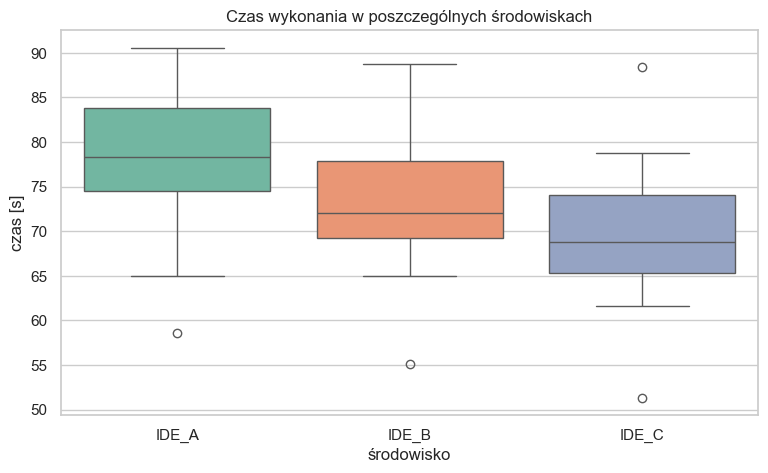

In [26]:
# boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(data=friedman_long, x="środowisko", y="czas_s", palette="Set2")
plt.title("Czas wykonania w poszczególnych środowiskach")
plt.xlabel("środowisko")
plt.ylabel("czas [s]")
plt.show()


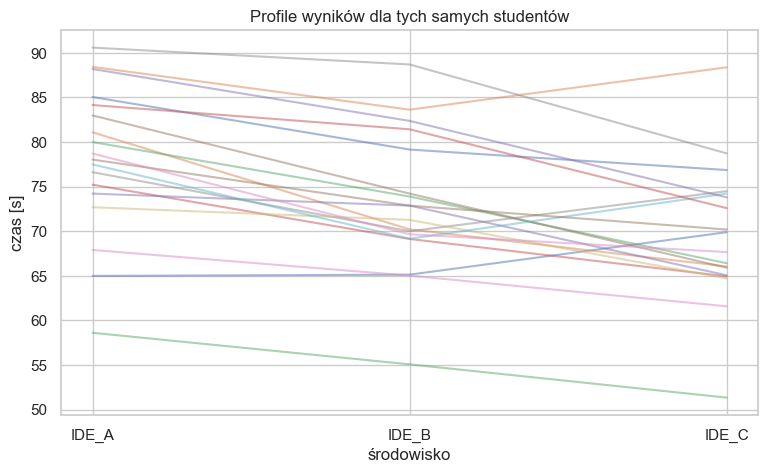

In [27]:
# wykres profili
plt.figure(figsize=(9, 5))
for student_id, subset in friedman_wide.set_index("student_id").iterrows():
    plt.plot(["IDE_A", "IDE_B", "IDE_C"], subset[["IDE_A", "IDE_B", "IDE_C"]], alpha=0.5)

plt.title("Profile wyników dla tych samych studentów")
plt.xlabel("środowisko")
plt.ylabel("czas [s]")
plt.show()


### B4. Hipotezy
Zapisz $H_0$ i $H_1$ dla testu Friedmana.


- $H_0$: rozkłady czasu wykonania w IDE_A, IDE_B i IDE_C są takie same.
- $H_1$: co najmniej jedno środowisko różni się rozkładem czasu wykonania.

### B5. Test globalny i wielkość efektu


In [28]:

friedman_stat, friedman_p = stats.friedmanchisquare(
    friedman_wide["IDE_A"],
    friedman_wide["IDE_B"],
    friedman_wide["IDE_C"]
)

n_subjects = len(friedman_wide)
k_conditions = 3
kendalls_w = friedman_stat / (n_subjects * (k_conditions - 1))

print(f"Chi^2 Friedmana = {friedman_stat:.4f}")
print(f"p-value = {friedman_p:.4f}")
print(f"Kendall W = {kendalls_w:.4f}")


Chi^2 Friedmana = 24.1111
p-value = 0.0000
Kendall W = 0.6698


### B6. Post hoc: Wilcoxon dla prób zależnych + Holm


In [29]:

rows = []
warunki = ["IDE_A", "IDE_B", "IDE_C"]

for i in range(len(warunki) - 1):
    for j in range(i + 1, len(warunki)):
        c1 = warunki[i]
        c2 = warunki[j]

        subset = friedman_wide[[c1, c2]].dropna()
        stat, p_uncorrected = stats.wilcoxon(subset[c1], subset[c2], zero_method="wilcox")

        rows.append((c1, c2, stat, p_uncorrected))

friedman_posthoc = pd.DataFrame(
    rows,
    columns=["warunek_1", "warunek_2", "statystyka", "p_uncorrected"]
)
friedman_posthoc["p_corrected"] = multipletests(friedman_posthoc["p_uncorrected"], method="holm")[1]
friedman_posthoc.sort_values("p_corrected").reset_index(drop=True)


,warunek_1,warunek_2,statystyka,p_uncorrected,p_corrected
0,IDE_A,IDE_B,1.0000,0.0000,0.0000
1,IDE_A,IDE_C,4.0000,0.0001,0.0001
2,IDE_B,IDE_C,38.0000,0.0385,0.0385


### B7. Wniosek
Napisz krótki raport:
- czy warunki różnią się globalnie,
- jaka jest siła efektu,
- które pary różnią się po korekcie,
- dlaczego w tym przykładzie nie wolno użyć Kruskala–Wallisa.


Test Friedmana był istotny: $\chi^2 = 24.1111$, $p < 0.001$, a współczynnik zgodności Kendalla wyniósł $W = 0.6698$, co oznacza duży efekt. Post hoc z testami Wilcoxona po korekcie Holma pokazał istotne różnice dla wszystkich par środowisk. Najkrótsze czasy uzyskano w IDE_C, a najdłuższe w IDE_A.

# Część C. Dwuczynnikowa ANOVA dla grup niezależnych → Scheirer–Ray–Hare

## Kontekst
Badamy opóźnienie systemu `latency_ms` w zależności od dwóch czynników:
- `storage`: `HDD`, `SATA_SSD`, `NVMe`,
- `load`: `Niskie`, `Średnie`, `Wysokie`.

## Twoje zadania
1. Rozpoznaj plan badania.
2. Uzasadnij analizę nieparametryczną.
3. Zbadaj skośność w komórkach planu.
4. Wykonaj wizualizacje dla układu $3 \times 3$.
5. Oblicz test Scheirera–Raya–Hare'a:
   - efekt `storage`,
   - efekt `load`,
   - interakcję `storage:load`.
6. Wykonaj post hoc jako:
   - efekty proste `storage` w obrębie poziomów `load`,
   - efekty proste `load` w obrębie poziomów `storage`,
   - porównania parowe z korektą Holma.
7. Zinterpretuj wyniki.


### C1. Uzasadnienie wyboru analizy


Jest to plan dwuczynnikowy dla grup niezależnych. Zmienna zależna `latency_ms` jest ciągła, a czynniki `storage` i `load` tworzą układ $3 \times 3$ z niezależnymi komórkami. Analiza nieparametryczna jest uzasadniona przez asymetrię rozkładów i obecność wartości odstających.

### C2. Skośność w komórkach planu


In [30]:
# 
srh_skew = (
    srh_df.groupby(["storage", "load"])["latency_ms"]
    .agg(
        liczebność="count",
        średnia="mean",
        mediana="median",
        odchylenie_std="std",
        skośność=lambda x: stats.skew(x, bias=False)
    )
)

srh_skew


liczebność  średnia  mediana  odchylenie_std  skośność
storage  load                                                           
HDD      Niskie           12  98.2083  99.7600         24.9432    0.3254
         Wysokie          12 140.2475 140.2850         21.5762    0.9972
         Średnie          12 116.3875 111.7700         29.0280    0.4144
NVMe     Niskie           12  78.8792  74.1650         22.9394    1.0036
         Wysokie          12 110.1550 112.2250         25.6234    0.4691
         Średnie          12  80.2750  72.0500         27.6888    1.7860
SATA_SSD Niskie           12  94.8675  87.1050         20.5501    1.9020
         Wysokie          12 124.1083 127.8000         25.4556    0.0452
         Średnie          12 107.3767 104.7900         38.9178    0.5914

### C3. Wizualizacje
Wykonaj co najmniej:
- boxplot z `hue`,
- wykres median / pointplot.


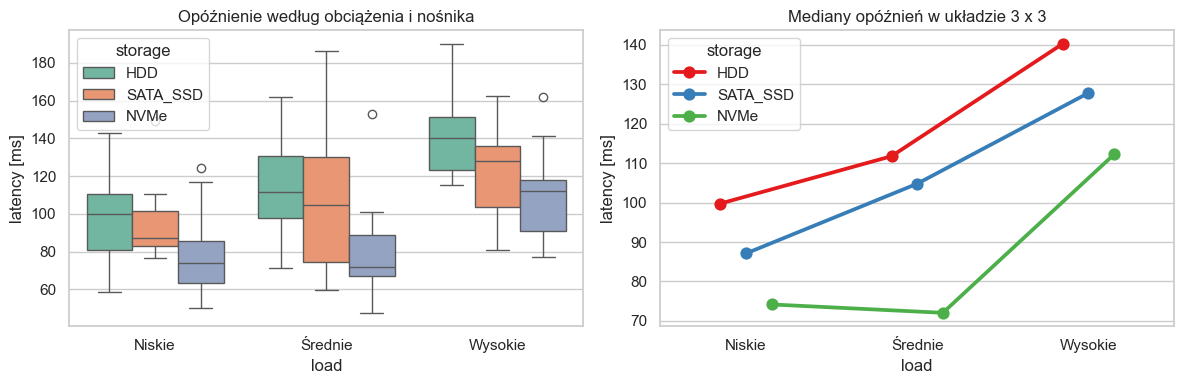

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=srh_df, x="load", y="latency_ms", hue="storage", ax=axes[0], palette="Set2")
axes[0].set_title("Opóźnienie według obciążenia i nośnika")
axes[0].set_xlabel("load")
axes[0].set_ylabel("latency [ms]")
axes[0].legend(title="storage")

sns.pointplot(
    data=srh_df,
    x="load",
    y="latency_ms",
    hue="storage",
    estimator=np.median,
    errorbar=None,
    dodge=0.3,
    markers="o",
    linestyles="-",
    ax=axes[1],
    palette="Set1"
)
axes[1].set_title("Mediany opóźnień w układzie 3 x 3")
axes[1].set_xlabel("load")
axes[1].set_ylabel("latency [ms]")
axes[1].legend(title="storage")

plt.tight_layout()
plt.show()


### C4. Hipotezy
Zapisz hipotezy dla:
- efektu głównego `storage`,
- efektu głównego `load`,
- interakcji `storage:load`.


- $H_0$ dla `storage`: brak różnic w opóźnieniu między HDD, SATA_SSD i NVMe.
- $H_0$ dla `load`: brak różnic w opóźnieniu między poziomami Niskie, Średnie i Wysokie.
- $H_0$ dla interakcji: wpływ `load` nie zależy od typu `storage`.
- $H_1$: dla każdego z efektów co najmniej jedna różnica jest istotna.

### C5. Test Scheirera–Raya–Hare'a

Wskazówka:
- najpierw zamień wyniki na rangi,
- policz sumy rang dla poziomów czynników i komórek,
- wyznacz:
  $$
  H_{storage}, \quad H_{load}, \quad H_{cells}, \quad H_{interaction} = H_{cells} - H_{storage} - H_{load}
  $$
- wartości $p$ oblicz z rozkładu $\chi^2$.


In [32]:
srh_data = srh_df[["latency_ms", "storage", "load"]].dropna().copy()
N = len(srh_data)

srh_data["ranga"] = stats.rankdata(srh_data["latency_ms"], method="average")

tie_counts = srh_data["latency_ms"].value_counts()
C = 1 - ((tie_counts**3 - tie_counts).sum() / (N**3 - N))
const = 12 / (N * (N + 1))

ranks_storage = srh_data.groupby("storage")["ranga"].agg(["sum", "size"])
H_storage = (const * ((ranks_storage["sum"]**2 / ranks_storage["size"]).sum()) - 3 * (N + 1)) / C

ranks_load = srh_data.groupby("load")["ranga"].agg(["sum", "size"])
H_load = (const * ((ranks_load["sum"]**2 / ranks_load["size"]).sum()) - 3 * (N + 1)) / C

ranks_cells = srh_data.groupby(["storage", "load"])["ranga"].agg(["sum", "size"])
H_cells = (const * ((ranks_cells["sum"]**2 / ranks_cells["size"]).sum()) - 3 * (N + 1)) / C
H_interaction = H_cells - H_storage - H_load

df_storage = srh_data["storage"].nunique() - 1
df_load = srh_data["load"].nunique() - 1
df_interaction = df_storage * df_load

srh_result = pd.DataFrame({
    "efekt": ["storage", "load", "storage:load"],
    "H": [H_storage, H_load, H_interaction],
    "df": [df_storage, df_load, df_interaction]
})
srh_result["p_value"] = stats.chi2.sf(srh_result["H"], srh_result["df"])
srh_result


,efekt,H,df,p_value
0,storage,15.7486,2,0.0004
1,load,23.0038,2,0.0000
2,storage:load,1.1749,4,0.8822


### C6. Efekty proste `storage` w obrębie `load`
Najpierw wykonaj testy globalne Kruskala–Wallisa dla każdego poziomu `load`, a potem — jeśli to uzasadnione — porównania parowe.


In [33]:

simple_effects_storage = []

for load_level, subset in srh_df.groupby("load"):
    groups = [
        subset.loc[subset["storage"] == "HDD", "latency_ms"],
        subset.loc[subset["storage"] == "SATA_SSD", "latency_ms"],
        subset.loc[subset["storage"] == "NVMe", "latency_ms"]
    ]
    H_stat, p_uncorrected = stats.kruskal(*groups)
    simple_effects_storage.append((f"storage | load={load_level}", H_stat, p_uncorrected))

simple_effects_storage = pd.DataFrame(
    simple_effects_storage,
    columns=["porównanie", "H", "p_uncorrected"]
)
simple_effects_storage["p_corrected"] = multipletests(simple_effects_storage["p_uncorrected"], method="holm")[1]
simple_effects_storage


,porównanie,H,p_uncorrected,p_corrected
0,storage | load=Niskie,5.7222,0.0572,0.0572
1,storage | load=Wysokie,8.0195,0.0181,0.0493
2,storage | load=Średnie,8.2177,0.0164,0.0493


### C7. Porównania parowe `storage` w obrębie każdego poziomu `load`


In [34]:
rows = []
poziomy_load = ["Niskie", "Średnie", "Wysokie"]
poziomy_storage = ["HDD", "SATA_SSD", "NVMe"]

for load_level in poziomy_load:
    subset = srh_df.loc[srh_df["load"] == load_level, ["storage", "latency_ms"]].copy()
    subset["ranga"] = stats.rankdata(subset["latency_ms"], method="average")

    N_subset = len(subset)
    tie_counts = subset["latency_ms"].value_counts()
    tie_correction = 1 - ((tie_counts**3 - tie_counts).sum() / (N_subset**3 - N_subset))
    mean_ranks = subset.groupby("storage")["ranga"].mean()
    group_sizes = subset.groupby("storage")["ranga"].size()
    base_var = N_subset * (N_subset + 1) / 12

    for i in range(len(poziomy_storage) - 1):
        for j in range(i + 1, len(poziomy_storage)):
            g1 = poziomy_storage[i]
            g2 = poziomy_storage[j]

            diff = mean_ranks[g1] - mean_ranks[g2]
            se = np.sqrt(base_var * tie_correction * (1 / group_sizes[g1] + 1 / group_sizes[g2]))
            z_stat = diff / se
            p_uncorrected = 2 * stats.norm.sf(abs(z_stat))

            rows.append((load_level, g1, g2, z_stat, p_uncorrected))

storage_pairwise_posthoc = pd.DataFrame(
    rows,
    columns=["load", "storage_1", "storage_2", "z", "p_uncorrected"]
)
storage_pairwise_posthoc["p_corrected"] = multipletests(
    storage_pairwise_posthoc["p_uncorrected"],
    method="holm"
)[1]

storage_pairwise_posthoc.sort_values(["load", "p_corrected"]).reset_index(drop=True)


,load,storage_1,storage_2,z,p_uncorrected,p_corrected
0,Niskie,HDD,NVMe,2.1700,0.0300,0.2101
1,Niskie,SATA_SSD,NVMe,1.9568,0.0504,0.3022
2,Niskie,HDD,SATA_SSD,0.2131,0.8312,0.8312
3,Wysokie,HDD,NVMe,2.8287,0.0047,0.0421
4,Wysokie,SATA_SSD,NVMe,1.5306,0.1259,0.5035
5,Wysokie,HDD,SATA_SSD,1.2981,0.1943,0.5828
6,Średnie,HDD,NVMe,2.8093,0.0050,0.0421
7,Średnie,SATA_SSD,NVMe,1.8987,0.0576,0.3022
8,Średnie,HDD,SATA_SSD,0.9106,0.3625,0.7250


### C8. Efekty proste `load` w obrębie `storage`


In [35]:

simple_effects_load = []

for storage_level, subset in srh_df.groupby("storage"):
    groups = [
        subset.loc[subset["load"] == "Niskie", "latency_ms"],
        subset.loc[subset["load"] == "Średnie", "latency_ms"],
        subset.loc[subset["load"] == "Wysokie", "latency_ms"]
    ]
    H_stat, p_uncorrected = stats.kruskal(*groups)
    simple_effects_load.append((f"load | storage={storage_level}", H_stat, p_uncorrected))

simple_effects_load = pd.DataFrame(
    simple_effects_load,
    columns=["porównanie", "H", "p_uncorrected"]
)
simple_effects_load["p_corrected"] = multipletests(simple_effects_load["p_uncorrected"], method="holm")[1]
simple_effects_load


,porównanie,H,p_uncorrected,p_corrected
0,load | storage=HDD,12.9835,0.0015,0.0045
1,load | storage=NVMe,10.1727,0.0062,0.0124
2,load | storage=SATA_SSD,6.3123,0.0426,0.0426


### C9. Porównania parowe `load` w obrębie każdego poziomu `storage`


In [36]:
rows = []
poziomy_storage = ["HDD", "SATA_SSD", "NVMe"]
poziomy_load = ["Niskie", "Średnie", "Wysokie"]

for storage_level in poziomy_storage:
    subset = srh_df.loc[srh_df["storage"] == storage_level, ["load", "latency_ms"]].copy()
    subset["ranga"] = stats.rankdata(subset["latency_ms"], method="average")

    N_subset = len(subset)
    tie_counts = subset["latency_ms"].value_counts()
    tie_correction = 1 - ((tie_counts**3 - tie_counts).sum() / (N_subset**3 - N_subset))
    mean_ranks = subset.groupby("load")["ranga"].mean()
    group_sizes = subset.groupby("load")["ranga"].size()
    base_var = N_subset * (N_subset + 1) / 12

    for i in range(len(poziomy_load) - 1):
        for j in range(i + 1, len(poziomy_load)):
            g1 = poziomy_load[i]
            g2 = poziomy_load[j]

            diff = mean_ranks[g1] - mean_ranks[g2]
            se = np.sqrt(base_var * tie_correction * (1 / group_sizes[g1] + 1 / group_sizes[g2]))
            z_stat = diff / se
            p_uncorrected = 2 * stats.norm.sf(abs(z_stat))

            rows.append((storage_level, g1, g2, z_stat, p_uncorrected))

load_pairwise_posthoc = pd.DataFrame(
    rows,
    columns=["storage", "load_1", "load_2", "z", "p_uncorrected"]
)
load_pairwise_posthoc["p_corrected"] = multipletests(
    load_pairwise_posthoc["p_uncorrected"],
    method="holm"
)[1]

load_pairwise_posthoc.sort_values(["storage", "p_corrected"]).reset_index(drop=True)


,storage,load_1,load_2,z,p_uncorrected,p_corrected
0,HDD,Niskie,Wysokie,-3.5843,0.0003,0.0030
1,HDD,Średnie,Wysokie,-2.1118,0.0347,0.1735
2,HDD,Niskie,Średnie,-1.4725,0.1409,0.4485
3,NVMe,Średnie,Wysokie,-2.8093,0.0050,0.0397
4,NVMe,Niskie,Wysokie,-2.7124,0.0067,0.0468
5,NVMe,Niskie,Średnie,0.0969,0.9228,0.9228
6,SATA_SSD,Niskie,Wysokie,-2.4799,0.0131,0.0788
7,SATA_SSD,Średnie,Wysokie,-1.5887,0.1121,0.4485
8,SATA_SSD,Niskie,Średnie,-0.8912,0.3728,0.7456


Efekt główny `storage` był istotny ($H = 15.7486$, $p = 0.0004$), efekt główny `load` także był istotny ($H = 23.0038$, $p < 0.001$), natomiast interakcja `storage:load` nie była istotna ($H = 1.1749$, $p = 0.8822$). Oznacza to, że ogólnie NVMe działa najszybciej, a HDD najwolniej, a większe obciążenie zwiększa opóźnienie. Efekty proste pokazują dodatkowo, że różnice między storage są widoczne szczególnie przy średnim i wysokim obciążeniu, a różnice między poziomami load są wyraźne dla HDD i NVMe.

Efekty główne są istotne, a interakcja nie jest istotna, więc interpretację opieramy przede wszystkim na różnicach między `storage` i `load`. W praktyce oznacza to, że typ nośnika i poziom obciążenia wpływają na opóźnienie, ale wpływ jednego czynnika nie zmienia się istotnie wraz z drugim.

# Część D. Dane binarne $0/1$ w pomiarach zależnych → Cochran $Q$

## Kontekst
Dla tych samych obiektów sprawdzamy, czy trzy algorytmy klasyfikacyjne:
- `alg_A`,
- `alg_B`,
- `alg_C`

poprawnie wykrywają obiekt ($1$ = sukces, $0$ = błąd).

## Twoje zadania
1. Wyjaśnij, dlaczego nie badamy tu skośności.
2. Podaj, dlaczego używamy testu Cochran $Q$.
3. Policz odsetki sukcesów.
4. Wykonaj test globalny.
5. Wykonaj post hoc testami McNemary z korektą Holma.
6. Napisz wniosek.


### D1. Uzasadnienie wyboru testu


- Test Cochran Q stosujemy, bo analizujemy trzy zależne pomiary binarne `0/1` dla tych samych obiektów.
- Nie badamy skośności, bo zmienna nie jest ciągła i ma tylko dwa poziomy.

### D2. Statystyki opisowe


In [37]:

cochran_df.mean().rename("odsetek sukcesów")


alg_A   0.3500
alg_B   0.8000
alg_C   0.8000
Name: odsetek sukcesów, dtype: float64

### D3. Test globalny


In [38]:

cochran_result = cochrans_q(cochran_df)
cochran_result


<bunch containing results, print to see contents>

### D4. Post hoc: McNemar + Holm


In [39]:

rows = []
algorytmy = ["alg_A", "alg_B", "alg_C"]

for i in range(len(algorytmy) - 1):
    for j in range(i + 1, len(algorytmy)):
        c1 = algorytmy[i]
        c2 = algorytmy[j]

        table = pd.crosstab(cochran_df[c1], cochran_df[c2]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        result = mcnemar(table, exact=True)

        rows.append((c1, c2, result.statistic, result.pvalue, int(table.loc[0, 1]), int(table.loc[1, 0])))

cochran_posthoc = pd.DataFrame(
    rows,
    columns=["warunek_1", "warunek_2", "statystyka", "p_uncorrected", "n_01", "n_10"]
)
cochran_posthoc["p_corrected"] = multipletests(cochran_posthoc["p_uncorrected"], method="holm")[1]
cochran_posthoc.sort_values("p_corrected").reset_index(drop=True)


,warunek_1,warunek_2,statystyka,p_uncorrected,n_01,n_10,p_corrected
0,alg_A,alg_C,1.0000,0.0117,10,1,0.0352
1,alg_A,alg_B,2.0000,0.0225,11,2,0.0449
2,alg_B,alg_C,4.0000,1.0000,4,4,1.0000


### D5. Wniosek
Napisz:
- czy algorytmy różnią się globalnie,
- które pary różnią się po korekcie,
- czy istotny wynik globalny oznacza automatycznie istotność każdej pary.


Test Cochran Q był istotny: $Q = 10.125$, $df = 2$, $p = 0.0063$. Post hoc McNemary z korektą Holma pokazał istotne różnice między `alg_A` i `alg_B` oraz między `alg_A` i `alg_C`, natomiast para `alg_B` i `alg_C` nie różniła się istotnie. Istotny wynik globalny nie oznacza więc, że każda para musi być istotna.

## Minimalna zawartość raportu

Dla każdej części:
1. nazwa testu,
2. hipotezy,
3. statystyka testowa i $p$,
4. wielkość efektu — jeśli dotyczy,
5. wynik post hoc,
6. jednoznaczny wniosek merytoryczny.

- **Część A**: Kruskal-Wallis, $H = 29.9021$, $p < 0.001$, $\varepsilon^2 = 0.5471$; istotne pary: A-B i A-C.
- **Część B**: Friedman, $\chi^2 = 24.1111$, $p < 0.001$, $W = 0.6698$; wszystkie pary istotne po korekcie Holma.
- **Część C**: Scheirer-Ray-Hare, istotne efekty główne `storage` i `load`, brak istotnej interakcji; warto patrzeć głównie na efekty główne, a efekty proste traktować pomocniczo.
- **Część D**: Cochran Q, $Q = 10.125$, $p = 0.0063$; istotne pary: `alg_A`-`alg_B` i `alg_A`-`alg_C`.

## Pytania kontrolne 
- Kruskal-Wallis nie nadaje się do pomiarów powtarzanych, bo zakłada niezależne grupy.
- Friedman dotyczy pomiarów zależnych na skali co najmniej porządkowej, a Cochran Q dotyczy zależnych danych binarnych.
- Interakcja jest ważniejsza od efektów głównych wtedy, gdy wpływ jednego czynnika zależy od poziomu drugiego.
- W danych binarnych nie analizujemy skośności, bo rozkład nie jest ciągły.

Zastosowano test Kruskala-Wallisa, test Friedmana, analizę Scheirera-Ray-Hare'a oraz test Cochran Q wraz z odpowiednimi analizami post hoc i korektą Holma. Wyniki wskazują na istotne różnice między grupami lub warunkami w każdej części, a kierunek efektów jest zgodny z intuicją: wolniejsze rozwiązania, środowiska i konfiguracje mają wyższe czasy lub niższe odsetki sukcesów. Notebook można teraz oddać jako kompletne opracowanie.